<div align="center">

# 03 · Pronóstico de la demanda y días atípicos

*Hourly Energy Consumption (PJM Interconnection)*

</div>

---

**Entrada:** `data/processed/consumo_horario.parquet` (datos limpios, en MW reales) y, para la sección 12, `tipos_de_dia.parquet` (notebook `02_patrones`).
**Funciones:** `src/features.py`, `src/modeling.py`, `src/anomalies.py`
**Parámetros:** `src/config.py` (`HORIZONTE_HORAS`, `REZAGOS_HORAS`, `VENTANAS_HORAS`, `FECHA_CORTE`, `N_PLIEGUES`, `MESES_PLIEGUE`, `SEMILLA`, `UMBRAL_Z_MODIFICADO`, `TOLERANCIA_EPISODIO_DIAS`, `DESFASE_FIN_DE_HORA`)
**Salida:** `residuos_PJME.parquet` y `metricas_ventana_movil_PJME.parquet` (Parte A); `anomalias_PJME_diario.parquet`, `anomalias_PJME_lista.parquet` y `anomalias_PJME_episodios.parquet` (Parte B). `src/export.py` los exporta para el panel de Streamlit.

El notebook responde a **P3: ¿qué días se desvían de lo esperable?** en dos pasos. La **Parte A** construye lo esperable: un pronóstico a 24 horas, cuyo valor no está solo en la precisión sino en cuánto y cuándo se desvía la demanda real. La **Parte B** usa los residuos fuera de muestra de ese pronóstico para marcar los días atípicos y contrastarlos con episodios conocidos.

**Día operativo.** Las variables de calendario se calculan desde `Datetime − 1 h` (la hora va de 0 a 23), igual que en `02_patrones` y `01_datos`.

**Convención del residuo:** `residuo = real − predicción`. Positivo significa demanda por encima de lo esperable (`alta`) y negativo, por debajo (`baja`).

| Parte | Sección | Qué responde |
|---|---|---|
| A | 1 | Variables del modelo (calendario, rezagos y medias móviles) |
| A | 2 | División cronológica en entrenamiento y prueba |
| A | 3 | Modelo base (ayer a la misma hora, y la semana anterior) |
| A | 4 | XGBoost |
| A | 5 | Evaluación: partición única, real frente a pronóstico y ventana móvil (residuos fuera de muestra) |
| A | 6 | Análisis de errores por hora, mes y tipo de día, peores días e importancia de variables |
| B | 7 | Residuo diario |
| B | 8 | z modificado, umbral, sensibilidad y concentración |
| B | 9 | Lista de días atípicos |
| B | 10 | Línea de tiempo y casos hora a hora |
| B | 11 | Contraste con episodios conocidos |
| B | 12 | Relación con la forma del día (`02_patrones`) |
| B | 13 | Guardado |
| — | 14 | Conclusiones y limitaciones |

**Diseño del experimento**

| Parte A · Pronóstico | Decisión |
|---|---|
| Objetivo | Consumo horario (`MW`) de una región |
| Horizonte | 24 horas: para predecir la hora *t* solo se usa información hasta *t − 24* |
| División | Cronológica: entrenamiento antes de `FECHA_CORTE`, prueba desde esa fecha |
| Validación | Ventana móvil con entrenamiento creciente: bloques consecutivos de `MESES_PLIEGUE` meses, al menos `N_PLIEGUES` pliegues |
| Modelo base | El consumo de ayer a la misma hora |
| Modelo | XGBoost con variables de calendario, rezagos y medias móviles |
| Métricas | MAE y RMSE (en MW), MAPE (en %) y MASE (frente al pronóstico ingenuo de ayer a la misma hora) |

| Parte B · Anomalías | Decisión |
|---|---|
| Unidad | Un día operativo con sus 24 horas |
| Medida | Residuo medio del día, en % de la predicción media del día (`residuo_pct`), para que sea comparable entre épocas y regiones |
| Regla | z modificado = 0.6745 · (x − mediana) / MAD; atípico si \|z\| > `UMBRAL_Z_MODIFICADO` (3.5, Iglewicz y Hoaglin) |
| Validación | Contraste con episodios externos conocidos (huracán Sandy, vórtices polares, olas de calor), con fuente y verificación |
| Alcance | `PJME`, la región con residuos de la Parte A. Para otras regiones hay que repetir el proceso con cada una |

## 0. Configuración y carga

In [1]:
%load_ext autoreload
%autoreload 2

import holidays
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    PROCESSED_DIR, HORIZONTE_HORAS, REZAGOS_HORAS, VENTANAS_HORAS, FECHA_CORTE,
    N_PLIEGUES, MESES_PLIEGUE, DESFASE_FIN_DE_HORA, TOLERANCIA_EPISODIO_DIAS, UMBRAL_Z_MODIFICADO,
)
from src.features import ESTACIONES, agregar_variables_temporales, agregar_rezagos, agregar_medias_moviles
from src.modeling import (
    seleccionar_variables,
    dividir_train_test,
    construir_X_y,
    pronostico_base,
    entrenar_xgboost,
    predecir,
    comparar_modelos,
    importancia_variables,
    validar_ventana_movil,
)
from src.anomalies import (
    CONSTANTE_Z, contrastar_episodios, EPISODIOS_CONOCIDOS, detectar_atipicos, listar_atipicos,
    residuo_diario, z_modificado,
)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "legend.frameon": False})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DIAS = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

### Parámetros de este notebook

- **`REGION`:** región a pronosticar y analizar. Los residuos de la Parte A son los que consume la Parte B.
- **`PLIEGUES`:** número de pliegues de la ventana móvil (mínimo `N_PLIEGUES`). Con 6 pliegues de 12 meses los residuos cubren 2012-08 → 2018-08, que incluye episodios que la Parte B contrasta (huracán Sandy, vórtice polar de 2014, ola de frío de 2015).
- **`Z_POR_ESTACION`:** con `False`, el z modificado se calcula con todos los días de la región. Si el error del modelo es mayor en invierno que en primavera, los atípicos se concentrarán en invierno (la sección 8.2 lo comprueba). Con `True` se calcula dentro de cada estación, de modo que cada día se compara con los de su misma estación.
- **`N_ANOTADOS` y `N_CASOS`:** días anotados en la línea de tiempo y casos que se dibujan hora a hora.

In [2]:
REGION = 'PJME'     # región a pronosticar y analizar
PLIEGUES = 6        # >= N_PLIEGUES; con 6 pliegues de 12 meses los residuos cubren 2012-08 → 2018-08
assert PLIEGUES >= N_PLIEGUES

Z_POR_ESTACION = False
N_ANOTADOS = 8
N_CASOS = 4

In [3]:
df = pd.read_parquet(PROCESSED_DIR / "consumo_horario.parquet")
df = df[df['region'] == REGION]

print(f"{REGION}: {len(df):,} filas · {df['Datetime'].min():%Y-%m-%d} → {df['Datetime'].max():%Y-%m-%d}")
print(f"Horizonte: {HORIZONTE_HORAS} h · rezagos: {REZAGOS_HORAS} · ventanas: {VENTANAS_HORAS} · corte: {FECHA_CORTE}")

PJME: 145,392 filas · 2002-01-01 → 2018-08-03
Horizonte: 24 h · rezagos: [24, 48, 168] · ventanas: [24, 168] · corte: 2017-01-01


---
# Parte A · Pronóstico de la demanda

Este pronóstico es la **referencia de lo esperable**: lo que interesa es cuánto y cuándo se desvía la demanda real, no solo la precisión.

## 1. Variables

- **Calendario:** hora, día de la semana, mes, fin de semana y festivo, calculados con el **día operativo** (`Datetime − 1 h`; la hora va de 0 a 23). Se conocen de antemano.
- **Rezagos:** consumo de hace 24, 48 y 168 horas.
- **Medias móviles:** promedio de las 24 y 168 horas previas, desplazado 24 horas.

Todas las variables de historia respetan el horizonte: ninguna usa información posterior a *t − 24*.

In [4]:
df = agregar_variables_temporales(df)
df = agregar_rezagos(df)
df = agregar_medias_moviles(df)

variables = seleccionar_variables(df)
print("Variables del modelo:", variables)
print(f"Rezago mínimo: {min(REZAGOS_HORAS)} h (horizonte: {HORIZONTE_HORAS} h)")
df[['Datetime', 'fecha', 'MW'] + variables].head()

Variables del modelo: ['hora', 'dia_semana', 'mes', 'es_fin_de_semana', 'es_festivo', 'MW_lag_24', 'MW_lag_48', 'MW_lag_168', 'MW_media_24h', 'MW_media_168h']
Rezago mínimo: 24 h (horizonte: 24 h)


,Datetime,fecha,MW,hora,dia_semana,mes,es_fin_de_semana,es_festivo,MW_lag_24,MW_lag_48,MW_lag_168,MW_media_24h,MW_media_168h
0,2002-01-01 01:00:00,2002-01-01,30393.0,0,1,1,False,True,NaN,NaN,NaN,NaN,NaN
1,2002-01-01 02:00:00,2002-01-01,29265.0,1,1,1,False,True,NaN,NaN,NaN,NaN,NaN
2,2002-01-01 03:00:00,2002-01-01,28357.0,2,1,1,False,True,NaN,NaN,NaN,NaN,NaN
3,2002-01-01 04:00:00,2002-01-01,27899.0,3,1,1,False,True,NaN,NaN,NaN,NaN,NaN
4,2002-01-01 05:00:00,2002-01-01,28057.0,4,1,1,False,True,NaN,NaN,NaN,NaN,NaN


## 2. División en entrenamiento y prueba

La división es por fecha, nunca al azar: el modelo se entrena con el pasado y se evalúa con un futuro que no ha visto. Los rezagos se calcularon antes de dividir, así que las primeras horas de la prueba usan el final del entrenamiento (información que sí existiría en la práctica). Con la hora-fin, la prueba empieza en `2017-01-01 00:00`, que es la hora 23 del 2016-12-31: ese primer día operativo queda incompleto y se excluye de los análisis diarios (sección 6.4).

In [5]:
train, test = dividir_train_test(df)

X_train, y_train = construir_X_y(train)
X_test, y_test = construir_X_y(test)

print(f"X_train: {X_train.shape} · X_test: {X_test.shape}")

Entrenamiento: 131,495 filas (2002-01-01 → 2016-12-31)
Prueba:        13,897 filas (2017-01-01 → 2018-08-03)


Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
X_train: (131304, 10) · X_test: (13897, 10)


## 3. Modelo base

Referencias sencillas que cualquier modelo debe superar: el consumo de ayer a la misma hora (24 h) y el de la semana anterior (168 h). Sus métricas se muestran junto a las de XGBoost en la sección 5.1.

In [6]:
base_24h = pronostico_base(test, rezago=24).loc[X_test.index]
base_168h = pronostico_base(test, rezago=168).loc[X_test.index]

## 4. XGBoost

Se entrena con los valores por defecto de `entrenar_xgboost` (500 árboles, tasa de aprendizaje 0.05, profundidad 6). Los parámetros se pueden sobrescribir al llamar a la función.

In [7]:
modelo = entrenar_xgboost(X_train, y_train)
pred_xgb = predecir(modelo, X_test)

pred_xgb.head()

131495    29933.714844
131496    27649.357422
131497    27354.111328
131498    26812.207031
131499    26444.121094
Name: prediccion, dtype: float32

## 5. Evaluación

**MASE** compara el MAE con el error del pronóstico ingenuo de «ayer a la misma hora» medido en el entrenamiento: menor que 1 significa que el modelo se equivoca menos que ese pronóstico, y permite comparar regiones de distinto tamaño. Se calcula con la escala de 24 h incluso para el modelo base de 168 h.

### 5.1 Partición única (corte en `FECHA_CORTE`)

In [8]:
metricas = comparar_modelos(y_test, {
    'Base 24 h': base_24h,
    'Base 168 h': base_168h,
    'XGBoost': pred_xgb,
}, real_train=train['MW'])

mejora_mae = (1 - metricas.loc['XGBoost', 'MAE'] / metricas.loc['Base 24 h', 'MAE']) * 100
mejora_rmse = (1 - metricas.loc['XGBoost', 'RMSE'] / metricas.loc['Base 24 h', 'RMSE']) * 100
print(f"XGBoost reduce el MAE un {mejora_mae:.1f} % y el RMSE un {mejora_rmse:.1f} % respecto al modelo base de 24 h")
print(f"MASE de XGBoost: {metricas.loc['XGBoost', 'MASE']:.2f} (menor que 1: mejor que el pronóstico ingenuo)")
metricas.round(2)

XGBoost reduce el MAE un 19.1 % y el RMSE un 19.8 % respecto al modelo base de 24 h
MASE de XGBoost: 0.86 (menor que 1: mejor que el pronóstico ingenuo)


,MAE,RMSE,MAPE_%,MASE
Base 24 h,2300.08,3134.18,7.32,1.06
Base 168 h,3511.18,4793.98,10.99,1.63
XGBoost,1861.58,2512.52,5.89,0.86


### 5.2 Real frente a pronóstico

Ventana de dos semanas alrededor del mayor pico de consumo del periodo de prueba.

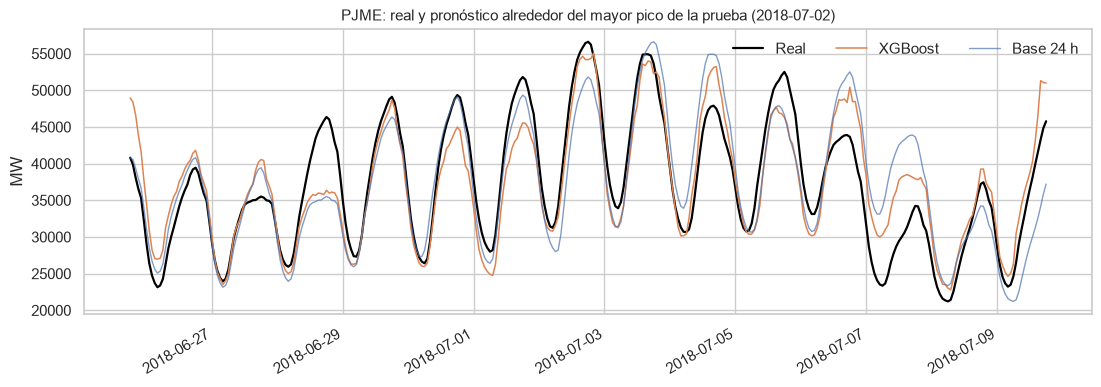

In [9]:
resultados = (
    test.loc[X_test.index, ['Datetime', 'fecha', 'MW', 'hora', 'mes', 'es_festivo', 'es_fin_de_semana']]
    .assign(xgboost=pred_xgb, base_24h=base_24h)
)
resultados['error_xgboost'] = (resultados['xgboost'] - resultados['MW']).abs()
resultados['error_base_24h'] = (resultados['base_24h'] - resultados['MW']).abs()

fecha_pico = resultados.loc[resultados['MW'].idxmax(), 'Datetime']
ventana = resultados[resultados['Datetime'].between(
    fecha_pico - pd.Timedelta(days=7), fecha_pico + pd.Timedelta(days=7))]

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(ventana['Datetime'], ventana['MW'], color='black', lw=1.6, label='Real')
ax.plot(ventana['Datetime'], ventana['xgboost'], color='C1', lw=1.1, label='XGBoost')
ax.plot(ventana['Datetime'], ventana['base_24h'], color='C0', lw=1, alpha=0.7, label='Base 24 h')
ax.set_title(f'{REGION}: real y pronóstico alrededor del mayor pico de la prueba ({fecha_pico:%Y-%m-%d})')
ax.set_ylabel('MW')
ax.legend(ncol=3)
fig.autofmt_xdate()
plt.show()

### 5.3 Validación en ventana móvil

Con una sola partición el resultado depende del periodo de prueba. Aquí el entrenamiento y la prueba se repiten en bloques consecutivos de `MESES_PLIEGUE` meses que terminan en la última fecha. Cada pliegue entrena con todo lo anterior y prueba en su bloque, así que los bloques no se solapan y cada hora se predice **una sola vez, fuera de muestra**.

**Criterio de cierre:** XGBoost supera al modelo base en todos los pliegues.

In [10]:
metricas_vm, residuos = validar_ventana_movil(df, n_pliegues=PLIEGUES)

mae_vm = metricas_vm['MAE'].unstack('modelo')
mase_vm = metricas_vm['MASE'].unstack('modelo')

tabla_vm = pd.DataFrame({
    'prueba_inicio': metricas_vm['inicio_prueba'].unstack('modelo')['XGBoost'],
    'prueba_fin': metricas_vm['fin_prueba'].unstack('modelo')['XGBoost'],
    'MAE_base': mae_vm['Base'],
    'MAE_XGBoost': mae_vm['XGBoost'],
    'mejora_MAE_%': (1 - mae_vm['XGBoost'] / mae_vm['Base']) * 100,
    'MASE_XGBoost': mase_vm['XGBoost'],
})
tabla_vm.index = tabla_vm.index.astype(int)

print("XGBoost supera al base en todos los pliegues:", bool((mae_vm['XGBoost'] < mae_vm['Base']).all()))
print("MASE de XGBoost menor que 1 en todos los pliegues:", bool((mase_vm['XGBoost'] < 1).all()))
tabla_vm.round(2)

Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0


Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0


Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0


Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0


Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0


Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0


El modelo supera al base en todos los pliegues: True
XGBoost supera al base en todos los pliegues: True
MASE de XGBoost menor que 1 en todos los pliegues: True


C:\Users\lukas\AppData\Local\Temp\ipykernel_20728\541222358.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  tabla_vm.round(2)


,prueba_inicio,prueba_fin,MAE_base,MAE_XGBoost,mejora_MAE_%,MASE_XGBoost
pliegue,,,,,,
1,2012-08-03,2013-08-03,2048.83,1551.19,24.29,0.72
2,2013-08-03,2014-08-03,2401.88,1723.19,28.26,0.80
3,2014-08-03,2015-08-03,2251.80,1688.23,25.03,0.78
4,2015-08-03,2016-08-03,2013.47,1580.75,21.49,0.73
5,2016-08-03,2017-08-03,2174.01,1727.46,20.54,0.80
6,2017-08-03,2018-08-03,2306.80,1883.74,18.34,0.87


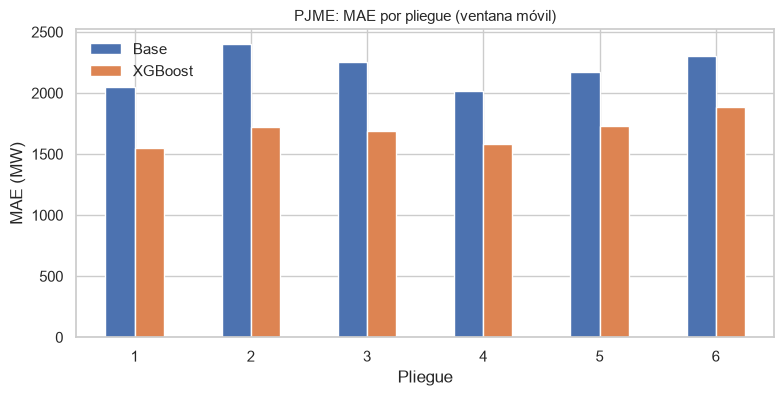

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
mae_vm.set_index(mae_vm.index.astype(int)).plot(kind='bar', ax=ax, rot=0)
ax.set_title(f'{REGION}: MAE por pliegue (ventana móvil)')
ax.set_xlabel('Pliegue')
ax.set_ylabel('MAE (MW)')
ax.legend(title='')
plt.show()

### 5.4 Residuos fuera de muestra

Se guardan para la Parte B (días atípicos) y para la página de pronóstico del panel.

In [12]:
print(f"Residuos: {len(residuos):,} horas · {residuos['Datetime'].min():%Y-%m-%d} → {residuos['Datetime'].max():%Y-%m-%d}")
print("Cada hora aparece una sola vez:", residuos['Datetime'].is_unique)

residuos.to_parquet(PROCESSED_DIR / f"residuos_{REGION}.parquet", index=False)
metricas_vm.reset_index().to_parquet(PROCESSED_DIR / f"metricas_ventana_movil_{REGION}.parquet", index=False)
residuos.head()

Residuos: 52,584 horas · 2012-08-03 → 2018-08-03
Cada hora aparece una sola vez: True


,Datetime,real,prediccion,residuo,pliegue
92808,2012-08-03 01:00:00,34983.0,31643.828125,3339.171875,1
92809,2012-08-03 02:00:00,32651.0,29446.089844,3204.910156,1
92810,2012-08-03 03:00:00,31038.0,28166.806641,2871.193359,1
92811,2012-08-03 04:00:00,30123.0,27566.251953,2556.748047,1
92812,2012-08-03 05:00:00,30089.0,27493.123047,2595.876953,1


## 6. Análisis de errores

Error absoluto medio (MAE, en MW) del modelo base y de XGBoost según la hora, el mes y el tipo de día, sobre la partición única.

### 6.1 Por hora del día

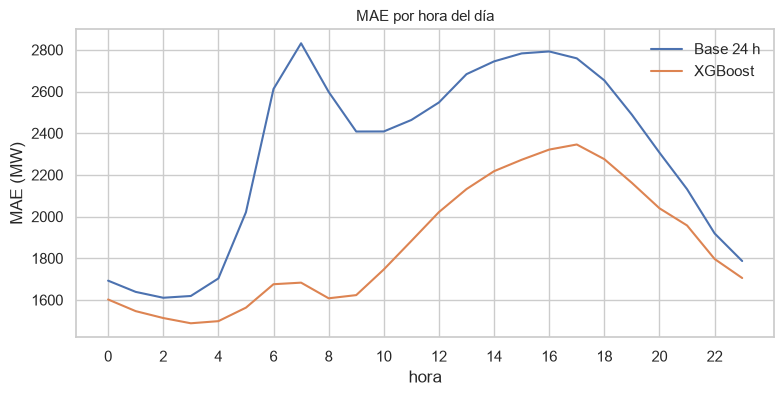

In [13]:
mae_hora = resultados.groupby('hora')[['error_base_24h', 'error_xgboost']].mean()
mae_hora.columns = ['Base 24 h', 'XGBoost']

fig, ax = plt.subplots(figsize=(9, 4))
mae_hora.plot(ax=ax)
ax.set_title('MAE por hora del día')
ax.set_xlabel('hora')
ax.set_ylabel('MAE (MW)')
ax.set_xticks(range(0, 24, 2))
ax.legend(title='')
plt.show()

### 6.2 Por mes

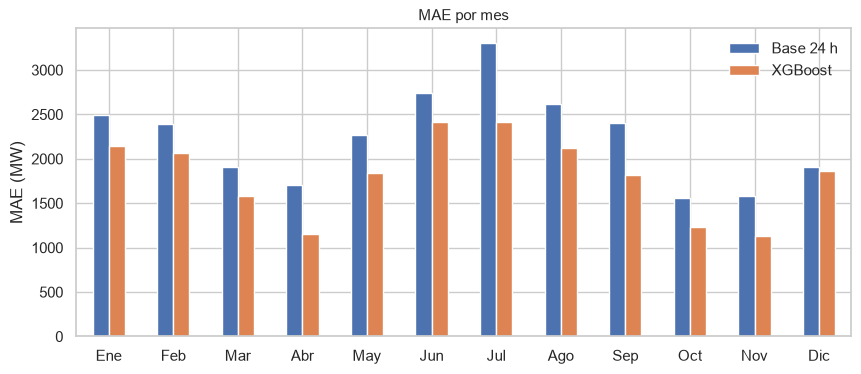

In [14]:
mae_mes = resultados.groupby('mes')[['error_base_24h', 'error_xgboost']].mean()
mae_mes.index = [MESES[m - 1] for m in mae_mes.index]
mae_mes.columns = ['Base 24 h', 'XGBoost']

fig, ax = plt.subplots(figsize=(10, 4))
mae_mes.plot(kind='bar', ax=ax, rot=0)
ax.set_title('MAE por mes')
ax.set_xlabel('')
ax.set_ylabel('MAE (MW)')
ax.legend(title='')
plt.show()

### 6.3 Por tipo de día

In [15]:
resultados['tipo_dia'] = np.select(
    [resultados['es_festivo'], resultados['es_fin_de_semana']],
    ['Festivo', 'Fin de semana'],
    default='Laborable',
)

(resultados.groupby('tipo_dia')[['error_base_24h', 'error_xgboost']].mean()
 .rename(columns={'error_base_24h': 'MAE Base 24 h', 'error_xgboost': 'MAE XGBoost'})
 .join(resultados['tipo_dia'].value_counts().rename('horas'))
 .round(1))

,MAE Base 24 h,MAE XGBoost,horas
tipo_dia,,,
Festivo,2701.2,1886.9,408
Fin de semana,2554.5,1906.9,3913
Laborable,2179.0,1842.0,9576


### 6.4 Los 10 días con mayor error

Los días son días operativos (`fecha`). Solo se consideran días completos (24 horas): el primer día de la prueba empieza en su hora 23 y su error no es comparable. En la sección 9 se cruzan con los días atípicos de la Parte B.

In [16]:
por_dia = (resultados.groupby('fecha')
           .agg(MAE_xgboost=('error_xgboost', 'mean'),
                MAE_base_24h=('error_base_24h', 'mean'),
                festivo=('es_festivo', 'first'),
                horas=('MW', 'size')))

peores = por_dia[por_dia['horas'] == 24].nlargest(10, 'MAE_xgboost').drop(columns='horas')
peores_fechas = peores.index                      # fechas reales, para cruzarlas en la sección 9
peores.index = peores.index.strftime('%Y-%m-%d')
peores.round(1)

,MAE_xgboost,MAE_base_24h,festivo
fecha,,,
2017-05-20,8097.7,12062.3,False
2018-06-03,6665.2,7405.4,False
2018-07-07,6161.3,10061.4,False
2017-07-29,5671.2,6826.7,False
2017-03-15,5143.6,3515.7,False
2017-09-28,5032.7,5605.8,False
2017-12-31,5000.1,1858.7,False
2018-05-29,4949.0,7582.1,False
2017-07-25,4938.2,4091.5,False


### 6.5 Importancia de las variables

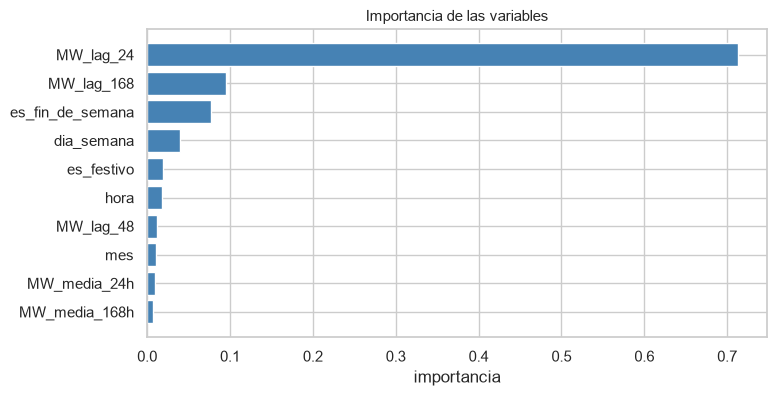

,importancia
MW_lag_24,0.713
MW_lag_168,0.095
es_fin_de_semana,0.077
dia_semana,0.040
es_festivo,0.019
hora,0.018
MW_lag_48,0.012
mes,0.011
MW_media_24h,0.009
MW_media_168h,0.006


In [17]:
importancia = importancia_variables(modelo, list(X_train.columns))

imp = importancia.sort_values('importancia')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.index, imp['importancia'], color='steelblue')
ax.set_title('Importancia de las variables')
ax.set_xlabel('importancia')
plt.show()

importancia.round(3)

---
# Parte B · Detección de días atípicos

Lo esperable es el pronóstico a 24 horas de la Parte A: un día es atípico cuando la demanda real se aleja mucho de lo que el modelo esperaba para ese día, medido solo con predicciones **fuera de muestra**.

## 7. Residuo diario

Se leen los residuos guardados en la sección 5.4. `residuo_diario` agrega los residuos horarios por día operativo y conserva solo los días con las 24 horas. El residuo en porcentaje se mide sobre la predicción (lo esperable), no sobre el valor real.

In [18]:
residuos = pd.read_parquet(PROCESSED_DIR / f"residuos_{REGION}.parquet")
residuos['fecha'] = (residuos['Datetime'] - DESFASE_FIN_DE_HORA).dt.normalize()   # día operativo

print(f"{len(residuos):,} horas · {residuos['Datetime'].min():%Y-%m-%d} → {residuos['Datetime'].max():%Y-%m-%d}")
print("Cada hora aparece una sola vez:", residuos['Datetime'].is_unique)
print("Pliegues:", sorted(int(p) for p in residuos['pliegue'].unique()))
residuos.head()

52,584 horas · 2012-08-03 → 2018-08-03
Cada hora aparece una sola vez: True
Pliegues: [1, 2, 3, 4, 5, 6]


,Datetime,real,prediccion,residuo,pliegue,fecha
0,2012-08-03 01:00:00,34983.0,31643.828125,3339.171875,1,2012-08-03
1,2012-08-03 02:00:00,32651.0,29446.089844,3204.910156,1,2012-08-03
2,2012-08-03 03:00:00,31038.0,28166.806641,2871.193359,1,2012-08-03
3,2012-08-03 04:00:00,30123.0,27566.251953,2556.748047,1,2012-08-03
4,2012-08-03 05:00:00,30089.0,27493.123047,2595.876953,1,2012-08-03


In [19]:
diario = residuo_diario(residuos, region=REGION)

pliegue_dia = residuos.groupby('fecha')['pliegue'].agg(lambda s: s.mode().iloc[0]).rename('pliegue')
diario = diario.merge(pliegue_dia, on='fecha', how='left')

print(f"{len(diario):,} días completos · {diario['fecha'].min():%Y-%m-%d} → {diario['fecha'].max():%Y-%m-%d}")
print("Cada fecha aparece una vez:", diario['fecha'].is_unique)
diario[['residuo_pct', 'residuo_medio_MW', 'residuo_hora_max_MW']].describe().round(2)

Días descartados por tener menos de 24 horas: 0


2,191 días completos · 2012-08-03 → 2018-08-02
Cada fecha aparece una vez: True


,residuo_pct,residuo_medio_MW,residuo_hora_max_MW
count,2191.00,2191.00,2191.00
mean,-0.59,-173.95,3378.92
std,5.54,1822.20,2058.86
min,-27.91,-7969.59,417.33
25%,-3.84,-1166.45,1951.47
50%,-1.00,-301.84,2893.04
75%,2.50,790.31,4224.46
max,25.02,8958.12,15200.15


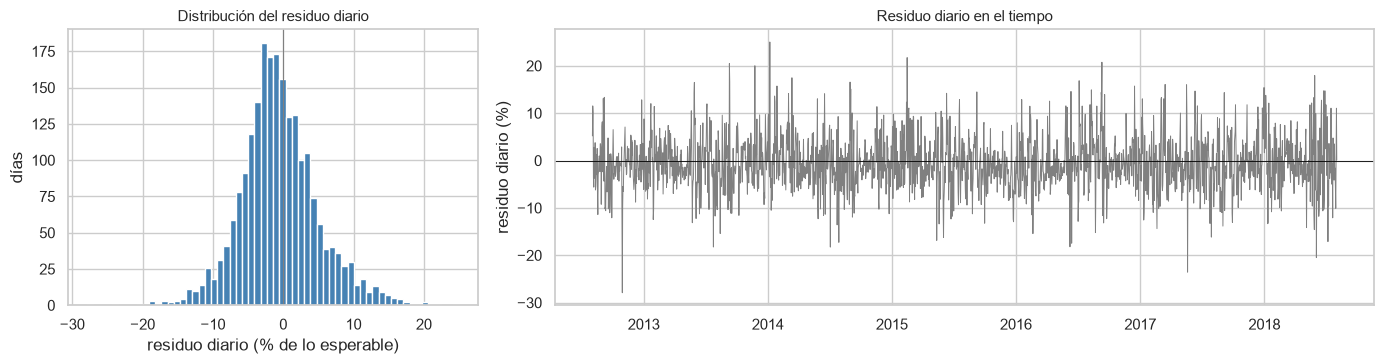

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1, 2]})

axes[0].hist(diario['residuo_pct'], bins=60, color='steelblue')
axes[0].axvline(0, color='gray', lw=0.8)
axes[0].set_title('Distribución del residuo diario')
axes[0].set_xlabel('residuo diario (% de lo esperable)')
axes[0].set_ylabel('días')

axes[1].plot(diario['fecha'], diario['residuo_pct'], color='gray', lw=0.7)
axes[1].axhline(0, color='black', lw=0.6)
axes[1].set_title('Residuo diario en el tiempo')
axes[1].set_ylabel('residuo diario (%)')

fig.tight_layout()
plt.show()

## 8. z modificado y umbral

El z modificado usa la **mediana y la MAD** (mediana de las desviaciones absolutas) en lugar de la media y la desviación estándar, así los propios atípicos no distorsionan la medida. Un día es atípico si su valor absoluto supera `UMBRAL_Z_MODIFICADO`.

In [21]:
marcado = detectar_atipicos(diario)
marcado['anio'] = marcado['fecha'].dt.year
marcado['mes'] = marcado['fecha'].dt.month
marcado['estacion'] = marcado['mes'].map(ESTACIONES)

if Z_POR_ESTACION:
    marcado['z_mod'] = marcado.groupby('estacion')['residuo_pct'].transform(z_modificado)
    marcado['es_atipico'] = marcado['z_mod'].abs() > UMBRAL_Z_MODIFICADO
    marcado['direccion'] = pd.Series(pd.NA, index=marcado.index, dtype='object')
    marcado.loc[marcado['es_atipico'] & (marcado['z_mod'] > 0), 'direccion'] = 'alta'
    marcado.loc[marcado['es_atipico'] & (marcado['z_mod'] < 0), 'direccion'] = 'baja'
    print(f"z modificado por estación: {int(marcado['es_atipico'].sum())} días atípicos")

print(marcado['direccion'].value_counts().rename('días'))

Días atípicos: 22 de 2191 (1.0 %)
direccion
alta    15
baja     7
Name: días, dtype: int64


### 8.1 Sensibilidad al umbral

Cuántos días se marcan con otros umbrales. Si el número cambia mucho entre 3.5 y 4, el criterio de corte es frágil y hay que decirlo.

,umbral,dias_atipicos,pct_dias
0,3.0,52,2.37
1,3.5,22,1.00
2,4.0,9,0.41
3,5.0,2,0.09


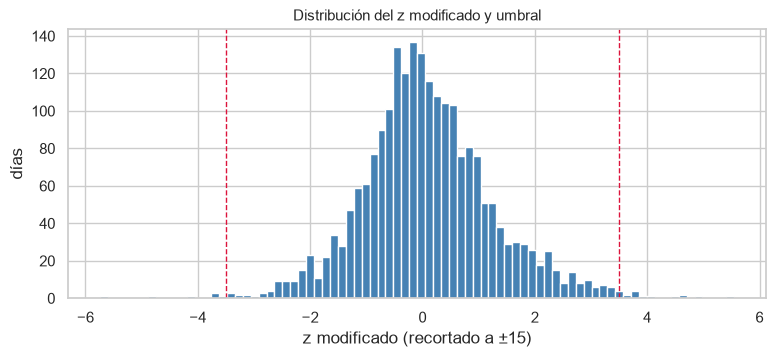

In [22]:
z = marcado['z_mod'].abs()
sensibilidad = pd.DataFrame({
    'umbral': [3.0, 3.5, 4.0, 5.0],
}).assign(
    dias_atipicos=lambda d: [int((z > u).sum()) for u in d['umbral']],
    pct_dias=lambda d: d['dias_atipicos'] / len(z) * 100,
)
display(sensibilidad.round(2))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(marcado['z_mod'].clip(-15, 15), bins=80, color='steelblue')
for s in (-UMBRAL_Z_MODIFICADO, UMBRAL_Z_MODIFICADO):
    ax.axvline(s, color='crimson', ls='--', lw=1)
ax.set_title('Distribución del z modificado y umbral')
ax.set_xlabel('z modificado (recortado a ±15)')
ax.set_ylabel('días')
plt.show()

### 8.2 ¿Los atípicos se concentran en alguna estación o pliegue?

Si el error del modelo no es homogéneo (por ejemplo, más alto en invierno, o mayor en los primeros pliegues que entrenan con menos historia), los atípicos reflejarán esa diferencia y no solo días raros.

In [23]:
print("Atípicos por estación")
por_estacion = marcado.groupby('estacion').agg(
    dias=('fecha', 'size'), atipicos=('es_atipico', 'sum'),
    mediana_pct=('residuo_pct', 'median'),
    MAD_pct=('residuo_pct', lambda s: (s - s.median()).abs().median()),
)
por_estacion['pct_atipicos'] = por_estacion['atipicos'] / por_estacion['dias'] * 100
display(por_estacion.round(2))

print("Atípicos por pliegue")
por_pliegue = marcado.groupby('pliegue').agg(
    dias=('fecha', 'size'), atipicos=('es_atipico', 'sum'),
    mediana_pct=('residuo_pct', 'median'),
    MAD_pct=('residuo_pct', lambda s: (s - s.median()).abs().median()),
)
por_pliegue['pct_atipicos'] = por_pliegue['atipicos'] / por_pliegue['dias'] * 100
display(por_pliegue.round(2))

Atípicos por estación


,dias,atipicos,mediana_pct,MAD_pct,pct_atipicos
estacion,,,,,
Invierno,541,4,-0.70,3.78,0.74
Otoño,546,5,-1.01,2.47,0.92
Primavera,552,6,-1.30,2.69,1.09
Verano,552,7,-0.89,3.85,1.27


Atípicos por pliegue


,dias,atipicos,mediana_pct,MAD_pct,pct_atipicos
pliegue,,,,,
1,365,3,-1.09,2.89,0.82
2,365,7,-1.01,3.54,1.92
3,365,2,-0.65,3.12,0.55
4,366,3,-1.74,2.68,0.82
5,365,5,-0.96,3.24,1.37
6,365,2,-0.78,3.51,0.55


**Lectura.** Un `MAD_pct` mucho mayor en una estación o pliegue indica que su error es más disperso. Si pasa, probar `Z_POR_ESTACION = True` y comparar la lista de la sección 9.

**Conclusión:** el error no se reparte por igual entre estaciones (el `MAD_pct` es ≈ 3.8 en invierno y verano frente a ≈ 2.5–2.7 en otoño y primavera), pero los atípicos no se concentran en ninguna: van de 0.7 % (invierno) a 1.3 % (verano), con solo 4 a 7 días por estación, y el invierno, una de las estaciones más dispersas, es la que menos tiene. Por pliegue la tasa va de 0.5 % a 1.9 %: el pliegue 2 reúne 7 de los 22 atípicos, pero con tan pocos casos esa diferencia es difícil de interpretar, y el pliegue 1, el de menos historia, tiene solo 3. No hay evidencia de que la lista refleje sobre todo el error del modelo en una estación o pliegue concreto, así que se mantiene `Z_POR_ESTACION = False`.

## 9. Lista de días atípicos

`listar_atipicos` ordena los días marcados de mayor a menor magnitud (\|z\|). Se añade el día de la semana y si es festivo federal, porque son las explicaciones de calendario más simples para un día raro.

In [24]:
lista = listar_atipicos(marcado)

anios = range(int(marcado['fecha'].dt.year.min()), int(marcado['fecha'].dt.year.max()) + 1)
festivos = pd.to_datetime(list(holidays.country_holidays('US', years=anios).keys()))

lista['dia_semana'] = lista['fecha'].dt.dayofweek.map(dict(enumerate(DIAS)))
lista['es_festivo'] = lista['fecha'].isin(festivos)
marcado['es_festivo'] = marcado['fecha'].isin(festivos)

print(f"{len(lista)} días atípicos de {len(marcado):,} ({len(lista) / len(marcado):.1%})")
lista[['fecha', 'dia_semana', 'es_festivo', 'direccion', 'residuo_pct', 'residuo_medio_MW',
       'residuo_hora_max_MW', 'z_mod']].head(20).round({'residuo_pct': 2, 'residuo_medio_MW': 2, 'residuo_hora_max_MW': 2, 'z_mod': 2})

22 días atípicos de 2,191 (1.0%)


C:\Users\lukas\AppData\Local\Temp\ipykernel_20728\1420966514.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  lista['dia_semana'] = lista['fecha'].dt.dayofweek.map(dict(enumerate(DIAS)))


,fecha,dia_semana,es_festivo,direccion,residuo_pct,residuo_medio_MW,residuo_hora_max_MW,z_mod
0,2012-10-30,Mar,False,baja,-27.91,-7722.94,11487.17,-5.74
1,2014-01-07,Mar,False,alta,25.02,8958.12,12443.58,5.55
2,2015-02-15,Dom,False,alta,21.73,7322.86,9229.63,4.85
3,2017-05-20,Sáb,False,baja,-23.56,-7969.59,15200.15,-4.81
4,2016-09-10,Sáb,False,alta,20.75,7042.55,11772.46,4.64
5,2013-09-10,Mar,False,alta,20.47,6368.34,13488.91,4.58
6,2013-11-24,Dom,False,alta,20.01,5515.01,6770.27,4.48
7,2018-06-03,Dom,False,baja,-20.49,-6641.35,12519.10,-4.16
8,2018-05-29,Mar,False,alta,17.95,5032.09,10743.71,4.04
9,2014-03-13,Jue,False,alta,17.47,5377.30,6706.32,3.94


In [25]:
tasa = marcado.groupby('es_festivo')['es_atipico'].agg(dias='size', atipicos='sum', tasa='mean')
tasa['tasa'] = tasa['tasa'] * 100
print("Tasa de atípicos (%) en festivos y no festivos")
tasa.round(2)

Tasa de atípicos (%) en festivos y no festivos


,dias,atipicos,tasa
es_festivo,,,
False,2126,21,0.99
True,65,1,1.54


### 9.1 ¿Coinciden con los días de mayor error del pronóstico?

Cruce de los 10 días con mayor error de la sección 6.4 (partición única, modelo entrenado hasta 2016) con la lista de atípicos (ventana móvil). Son dos medidas distintas del mismo fenómeno: el MAE diario mide cuánto falla el modelo en valor absoluto y el z modificado compara el residuo de cada día con el de los demás días de la región.

In [26]:
cruce_peores = peores[['MAE_xgboost', 'MAE_base_24h']].join(
    pd.Series(peores_fechas.isin(lista['fecha']), index=peores.index, name='es_atipico'))

print(f"{int(cruce_peores['es_atipico'].sum())} de los 10 días con mayor error también son días atípicos")
cruce_peores.round(1)

4 de los 10 días con mayor error también son días atípicos


,MAE_xgboost,MAE_base_24h,es_atipico
fecha,,,
2017-05-20,8097.7,12062.3,True
2018-06-03,6665.2,7405.4,True
2018-07-07,6161.3,10061.4,False
2017-07-29,5671.2,6826.7,False
2017-03-15,5143.6,3515.7,True
2017-09-28,5032.7,5605.8,False
2017-12-31,5000.1,1858.7,False
2018-05-29,4949.0,7582.1,True
2017-07-25,4938.2,4091.5,False


**Lectura.** En la ejecución anterior coinciden al menos cuatro de los diez días: 2017-05-20 (el de mayor error del modelo, con un MAE de 8 098 MW, y también el cuarto atípico por magnitud), 2018-06-03, 2018-05-29 y 2017-03-15. Los días de mayor error del pronóstico y los atípicos son en buena parte los mismos, lo que indica que el residuo captura lo que el modelo no puede anticipar. Cabe esperar coincidencias imperfectas porque los modelos son distintos (el de la partición única entrena hasta 2016 y los de la ventana móvil entrenan con cada pliegue) y porque un día puede tener un error absoluto alto sin ser raro respecto a lo habitual de su época.

## 10. Línea de tiempo y casos

La banda azul es el rango que no se marca como atípico (mediana ± umbral × MAD / 0.6745, solo cuando el z se calcula con todos los días). Los puntos resaltados son los atípicos: naranja si la demanda superó lo esperable y verde si quedó por debajo. Se anotan los de mayor magnitud.

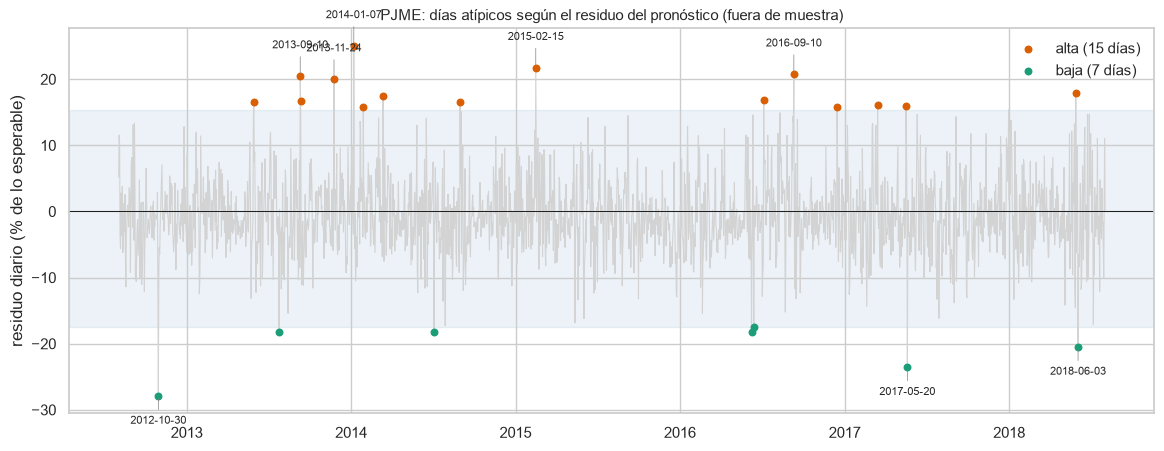

In [27]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(marcado['fecha'], marcado['residuo_pct'], color='lightgray', lw=0.8)

if not Z_POR_ESTACION:
    med = marcado['residuo_pct'].median()
    mad = (marcado['residuo_pct'] - med).abs().median()
    lim = UMBRAL_Z_MODIFICADO * mad / CONSTANTE_Z
    ax.axhspan(med - lim, med + lim, color='steelblue', alpha=0.10, zorder=0)

for direccion, color in [('alta', '#d95f02'), ('baja', '#1b9e77')]:
    s = marcado[marcado['direccion'] == direccion]
    ax.scatter(s['fecha'], s['residuo_pct'], color=color, s=22, zorder=3, label=f"{direccion} ({len(s)} días)")

for fila in lista.head(N_ANOTADOS).itertuples():
    ax.annotate(f"{fila.fecha:%Y-%m-%d}", (fila.fecha, fila.residuo_pct),
                xytext=(0, 20 if fila.residuo_pct > 0 else -20), textcoords='offset points',
                ha='center', fontsize=8, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

ax.axhline(0, color='black', lw=0.6)
ax.set_title(f'{REGION}: días atípicos según el residuo del pronóstico (fuera de muestra)')
ax.set_ylabel('residuo diario (% de lo esperable)')
ax.legend(loc='upper right')
plt.show()

### Los casos principales, hora a hora

Real y pronóstico en los días de mayor magnitud, con una ventana de ±3 días. La franja marca el día atípico.

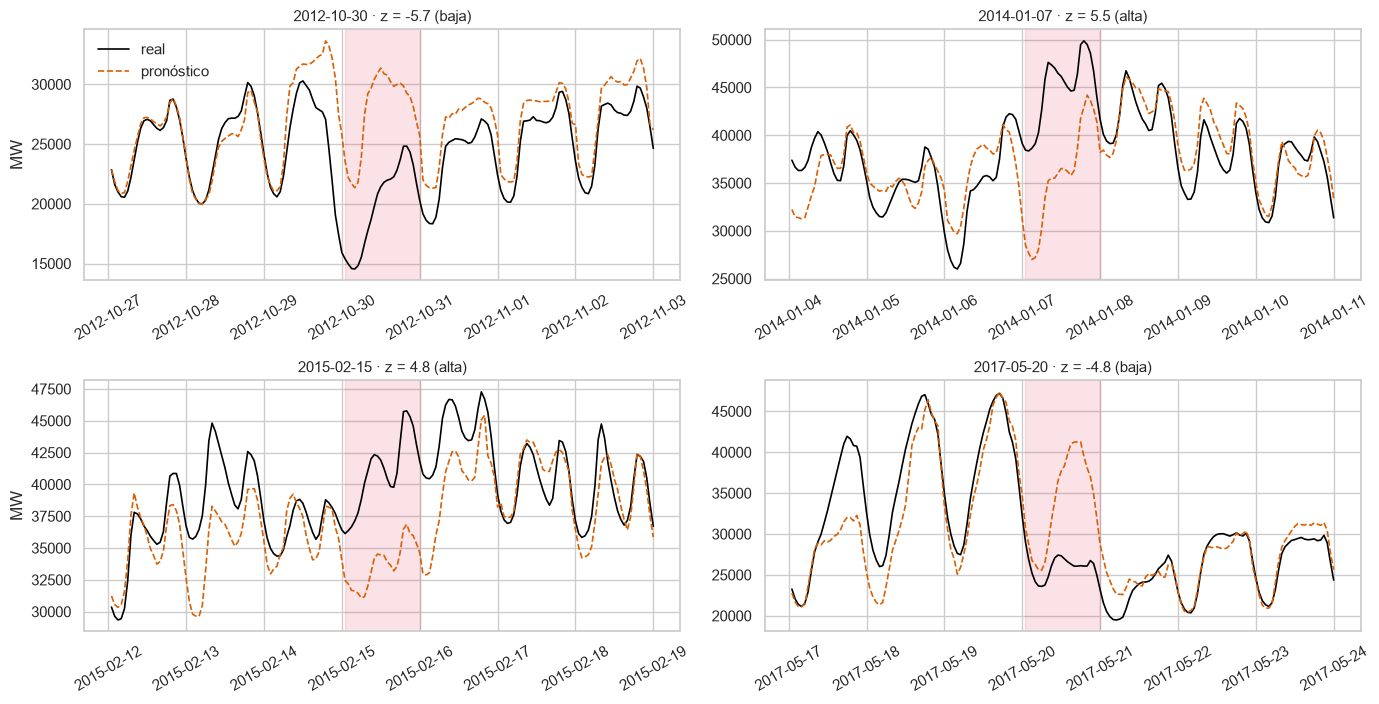

In [28]:
casos = lista.head(N_CASOS)
ncols = 2
nrows = int(np.ceil(len(casos) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.6 * nrows), squeeze=False)

for ax, fila in zip(axes.flat, casos.itertuples()):
    ventana = residuos[(residuos['fecha'] >= fila.fecha - pd.Timedelta(days=3)) &
                       (residuos['fecha'] <= fila.fecha + pd.Timedelta(days=3))]
    ax.plot(ventana['Datetime'], ventana['real'], color='black', lw=1.2, label='real')
    ax.plot(ventana['Datetime'], ventana['prediccion'], color='#d95f02', ls='--', lw=1.2, label='pronóstico')
    ax.axvspan(fila.fecha + pd.Timedelta(hours=1), fila.fecha + pd.Timedelta(days=1),
               color='crimson', alpha=0.12)
    ax.set_title(f"{fila.fecha:%Y-%m-%d} · z = {fila.z_mod:.1f} ({fila.direccion})", fontsize=11)
    ax.tick_params(axis='x', rotation=30)
for ax in axes.flat[len(casos):]:
    ax.axis('off')
for ax in axes[:, 0]:
    ax.set_ylabel('MW')
axes[0, 0].legend()

fig.tight_layout()
plt.show()

**Interpretación.** Los cuatro días de mayor magnitud se reparten entre dos de demanda por debajo de lo esperable y dos por encima. Sandy (2012-10-30, −27.9 %, z = −5.74) es el caso más claro de demanda baja: la real cayó a unos 15 000 MW frente a unos 30 000 esperados, coherente con los cortes de luz del huracán. El 2014-01-07 (+25.0 %, z = 5.55, vórtice polar) y el 2015-02-15 (+21.7 %, z = 4.85, ola de frío de febrero de 2015) son de demanda por encima: el 2014-01-07 la real llegó a cerca de 50 000 MW con un pronóstico muy inferior, es decir, el modelo no anticipó la intensidad del frío. El cuarto, el sábado 2017-05-20 (−23.6 %, z = −4.81), no corresponde a ningún episodio de la tabla: la real quedó en ≈ 27 000 MW y es el día con el mayor error en una sola hora (≈ 15 200 MW), lo que sugiere un cambio brusco de temperatura respecto al día anterior, aunque sin temperatura en el dataset es solo una hipótesis. No hay un patrón de un solo signo: depende del evento (frío extremo da demanda por encima, un apagón por tormenta da demanda por debajo), aunque en el conjunto de los 22 días atípicos predominan los altos (15 frente a 7).

## 11. Contraste con episodios conocidos

Un detector de anomalías solo es creíble si encuentra eventos que se conocen por otra vía. Se contrasta cada episodio con los días atípicos, con un margen de `TOLERANCIA_EPISODIO_DIAS` días. Los episodios fuera del rango cubierto por los residuos se marcan como **fuera de rango** (no evaluados), distinto de **sin coincidencia** (evaluados y no detectados).

Cada episodio lleva su `fuente` y si sus fechas están `verificado`. Las fechas se tomaron de fuentes públicas (PJM, NERC, EIA, prensa especializada); las que no tienen fuente deben verificarse antes de citarlas en el informe. La tabla se define una sola vez, en `EPISODIOS_CONOCIDOS` de `src/anomalies.py`.

In [29]:
EPISODIOS = EPISODIOS_CONOCIDOS

contraste = contrastar_episodios(
    lista, EPISODIOS,
    fecha_min=marcado['fecha'].min(), fecha_max=marcado['fecha'].max(),
)

margen = pd.Timedelta(days=TOLERANCIA_EPISODIO_DIAS)

def direcciones_detectadas(ep):
    dentro = lista[(lista['fecha'] >= ep['inicio'] - margen) & (lista['fecha'] <= ep['fin'] + margen)]
    return ', '.join(sorted(dentro['direccion'].dropna().unique()))

def coincide_direccion(ep):
    if ep['estado'] != 'coincide' or ep['direccion_esperada'] not in ('alta', 'baja'):
        return ''
    return 'Sí' if ep['direccion_esperada'] in ep['direccion_detectada'].split(', ') else 'No'

contraste['direccion_detectada'] = contraste.apply(direcciones_detectadas, axis=1)
contraste['coincide_direccion'] = contraste.apply(coincide_direccion, axis=1)

print(f"Rango cubierto por los residuos: {marcado['fecha'].min():%Y-%m-%d} → {marcado['fecha'].max():%Y-%m-%d}")
print(contraste['estado'].value_counts().to_string())
contraste[['episodio', 'inicio', 'fin', 'estado', 'n_dias_atipicos', 'max_abs_z', 'fechas',
           'direccion_esperada', 'direccion_detectada', 'coincide_direccion', 'verificado']].round({'max_abs_z': 2})

Rango cubierto por los residuos: 2012-08-03 → 2018-08-02
estado
coincide            5
sin coincidencia    3
fuera de rango      2


,episodio,inicio,fin,estado,n_dias_atipicos,max_abs_z,fechas,direccion_esperada,direccion_detectada,coincide_direccion,verificado
0,Ola de calor de agosto de 2006 (récord de PJM ...,2006-08-01,2006-08-03,fuera de rango,0,NaN,,alta,,,True
1,Ola de calor de julio de 2011,2011-07-20,2011-07-22,fuera de rango,0,NaN,,alta,,,True
2,Huracán Sandy,2012-10-29,2012-10-31,coincide,1,5.74,2012-10-30,baja,baja,Sí,True
3,Ola de calor de julio de 2013 (pico de PJM el ...,2013-07-15,2013-07-19,sin coincidencia,0,NaN,,alta,,,True
4,Calor de septiembre de 2013,2013-09-10,2013-09-12,coincide,2,4.58,"2013-09-10, 2013-09-11",alta,alta,Sí,True
5,Vórtice polar de enero de 2014 (récord inverna...,2014-01-06,2014-01-08,coincide,1,5.55,2014-01-07,alta,alta,Sí,True
6,Vórtice polar de fines de enero de 2014,2014-01-23,2014-01-29,coincide,1,3.57,2014-01-28,alta,alta,Sí,True
7,Ola de frío de febrero de 2015 (récord inverna...,2015-02-14,2015-02-21,coincide,1,4.85,2015-02-15,alta,alta,Sí,True
8,Tormenta Jonas,2016-01-22,2016-01-24,sin coincidencia,0,NaN,,por verificar,,,True
9,Ola de frío de enero de 2018,2018-01-01,2018-01-07,sin coincidencia,0,NaN,,alta,,,True


**Cómo leer la tabla.** `coincide` significa que al menos un día atípico cae dentro del episodio (± tolerancia). `direccion_detectada` es el signo de esos días y `coincide_direccion` indica si es el esperado: un frío o calor extremo debería dar residuos positivos (más demanda de la esperable) y Sandy, negativos (la demanda cayó por los cortes de luz). Un episodio sin coincidencia no se oculta: si el modelo ya anticipaba bien el frío o el calor (porque rezagos y medias móviles lo incorporan), el día no sale atípico aunque haya sido extremo.

### 11.1 Atípicos sin episodio conocido

Los días marcados que no caen en ningún episodio de la tabla. Sin temperatura en el dataset no se puede confirmar el clima de estos días; se listan como candidatos a revisar (festivos, cambios de horario, eventos locales).

In [30]:
def en_episodio(fecha):
    return bool(((EPISODIOS['inicio'] - margen <= fecha) & (fecha <= EPISODIOS['fin'] + margen)).any())

lista['en_episodio'] = lista['fecha'].map(en_episodio)
sin_episodio = lista[~lista['en_episodio']]
print(f"{len(sin_episodio)} de {len(lista)} atípicos no coinciden con ningún episodio de la tabla")
sin_episodio[['fecha', 'dia_semana', 'es_festivo', 'direccion', 'residuo_pct', 'z_mod']].head(15).round({'residuo_pct': 2, 'z_mod': 2})

16 de 22 atípicos no coinciden con ningún episodio de la tabla


,fecha,dia_semana,es_festivo,direccion,residuo_pct,z_mod
3,2017-05-20,Sáb,False,baja,-23.56,-4.81
4,2016-09-10,Sáb,False,alta,20.75,4.64
6,2013-11-24,Dom,False,alta,20.01,4.48
7,2018-06-03,Dom,False,baja,-20.49,-4.16
8,2018-05-29,Mar,False,alta,17.95,4.04
9,2014-03-13,Jue,False,alta,17.47,3.94
10,2016-07-05,Mar,False,alta,16.85,3.81
12,2014-08-31,Dom,False,alta,16.56,3.74
13,2013-05-30,Jue,False,alta,16.49,3.73
14,2014-07-04,Vie,True,baja,-18.27,-3.68


**Interpretación.** Se detectan 5 de los 8 episodios evaluados: Sandy (z = −5.74), el calor de septiembre de 2013 (dos días, |z| máximo de 4.58), los dos vórtices polares de enero de 2014 (z = 5.55 el día 7 y 3.57 el día 28) y la ola de frío de febrero de 2015 (z = 4.85). En los 5 el signo coincide con el esperado: positivo en frío y calor extremos y negativo en Sandy. No se detectan la ola de calor de julio de 2013, la ola de frío de enero de 2018 ni la tormenta Jonas, y los episodios de 2006 y 2011 quedan fuera del rango de los residuos. Que un episodio no salga atípico no significa que no haya sido extremo: el modelo pudo anticiparlo con sus rezagos y medias móviles (hipótesis).

De los 15 atípicos sin episodio que se listan (16 de los 22 en total no coinciden con ninguno), 10 son altos y 5 bajos, y los 5 bajos caen entre mayo y julio (2017-05-20, 2018-06-03, 2014-07-04, 2013-07-25 y 2016-06-08), compatible con días templados con menos aire acondicionado de lo esperable. Varios guardan relación con el calendario: el 2014-07-04 es festivo, el 2016-07-05 y el 2018-05-29 son el día siguiente a un festivo, y 5 de los 15 caen en fin de semana. Aun así, la tasa de atípicos en festivos (1.5 %, 1 día de 65) no es muy distinta de la de los demás días (1.0 %). Sin temperatura en el dataset no se puede confirmar la causa, y estos días quedan como candidatos a revisar contra el clima y el calendario.

## 12. Relación con la forma del día

`02_patrones` mide cuánto se aleja la **forma** de cada día de la de su tipo (`distancia_centroide`), mientras que este notebook mide cuánto se aleja el **nivel** de lo pronosticado. Un día puede ser raro en una, en la otra o en ambas. Esta sección solo corre si existe `tipos_de_dia.parquet`.

In [31]:
ruta_tipos = PROCESSED_DIR / "tipos_de_dia.parquet"
if ruta_tipos.exists():
    tipos_all = pd.read_parquet(ruta_tipos)
    tipos = tipos_all[tipos_all['region'] == REGION][['fecha', 'grupo', 'nombre_grupo', 'distancia_centroide']]
    cruce = marcado.merge(tipos, on='fecha', how='left')
    cruce['z_abs'] = cruce['z_mod'].abs()

    print(f"Días con tipo de día: {cruce['grupo'].notna().sum():,} de {len(cruce):,}")
    print("Correlación de Spearman entre |z| y la distancia al centro del grupo:",
          round(cruce[['z_abs', 'distancia_centroide']].corr(method='spearman').iloc[0, 1], 2))

    corte = cruce['distancia_centroide'].quantile(0.95)
    print(f"\nAtípico por residuo (filas) frente a forma lejana, percentil 95 de la distancia (columnas)")
    display(pd.crosstab(cruce['es_atipico'], cruce['distancia_centroide'] > corte))

    print("Atípicos por tipo de día")
    display(cruce.groupby('nombre_grupo')['es_atipico'].agg(dias='size', atipicos='sum', tasa='mean').round(3))
else:
    print("No existe tipos_de_dia.parquet: ejecutar antes el notebook 02_patrones.")

Días con tipo de día: 2,191 de 2,191
Correlación de Spearman entre |z| y la distancia al centro del grupo: 0.02

Atípico por residuo (filas) frente a forma lejana, percentil 95 de la distancia (columnas)


distancia_centroide,False,True
es_atipico,,
False,2067,102
True,14,8


Atípicos por tipo de día


,dias,atipicos,tasa
nombre_grupo,,,
Temporada fría (oct–may),1350,11,0.008
Verano (jun–sep),841,11,0.013


**Interpretación.** En conjunto, nivel y forma están poco relacionados: la correlación de Spearman entre |z| y la distancia al centro del grupo es 0.02, así que entre todos los días no hay una relación monótona. En la cola sí hay señal: 8 de los 22 atípicos (36 %) tienen una forma entre el 5 % más alejada de su grupo, frente a 102 de 2 169 días no atípicos (4.7 %). Los otros 14 atípicos (64 %) tienen una forma normal para su tipo de día y se distinguen solo por tener más o menos demanda de lo esperado. Los atípicos tampoco se concentran en un tipo de día (0.8 % en el grupo de temporada fría y 1.3 % en el de verano). Por tanto, las dos medidas son complementarias: el residuo detecta días de forma habitual pero con nivel inesperado, y la distancia al centro detecta días de forma rara que el nivel no marca.

### 12.1 Días de forma rara en cualquier región

`02_patrones` (sección 11) deja una lista de días cuya forma se aleja mucho de la de su grupo en alguna región, medida con `distancia_rel` (distancia dividida entre la mediana de su región, comparable entre regiones). Aquí se toman los 10 más lejanos que caen dentro del rango de los residuos y se mira qué pasó con el nivel de `PJME` esos días. Si `PJME` también es atípico, el evento probablemente afectó a toda la zona; si no, fue local o de forma más que de nivel.

In [32]:
if ruta_tipos.exists() and 'distancia_rel' in tipos_all.columns:
    en_rango = tipos_all['fecha'].between(marcado['fecha'].min(), marcado['fecha'].max())
    formas_raras = (tipos_all[en_rango].nlargest(10, 'distancia_rel')[['region', 'fecha', 'distancia_rel']]
                    .merge(marcado[['fecha', 'z_mod', 'es_atipico', 'direccion']], on='fecha', how='left')
                    .rename(columns={'z_mod': f'z_mod_{REGION}', 'es_atipico': f'atipico_{REGION}'}))
    display(formas_raras.round(2))
else:
    print("Falta tipos_de_dia.parquet o su columna distancia_rel: volver a ejecutar 02_patrones.")

C:\Users\lukas\AppData\Local\Temp\ipykernel_20728\1739959653.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(formas_raras.round(2))


,region,fecha,distancia_rel,z_mod_PJME,atipico_PJME,direccion
0,DOM,2015-03-07,4.02,0.85,False,<NA>
1,PJMW,2015-03-07,3.68,0.85,False,<NA>
2,AEP,2015-03-07,3.56,0.85,False,<NA>
3,EKPC,2017-02-10,3.47,1.36,False,<NA>
4,PJMW,2014-03-14,3.36,-0.10,False,<NA>
5,EKPC,2014-03-07,3.30,0.37,False,<NA>
6,EKPC,2018-01-07,3.27,2.30,False,<NA>
7,AEP,2014-03-14,3.25,-0.10,False,<NA>
8,DOM,2014-03-14,3.23,-0.10,False,<NA>
9,COMED,2016-06-12,3.21,0.00,False,<NA>


## 13. Guardado

| Archivo | Contenido |
|---|---|
| `residuos_PJME.parquet` | Residuos horarios fuera de muestra con su pliegue (sección 5.4) |
| `metricas_ventana_movil_PJME.parquet` | Métricas del modelo y del base por pliegue (sección 5.4) |
| `anomalias_PJME_diario.parquet` | Todos los días con residuo, z modificado, marca de atípico y dirección (contexto completo para la línea de tiempo del panel) |
| `anomalias_PJME_lista.parquet` | Solo los días atípicos, de mayor a menor magnitud |
| `anomalias_PJME_episodios.parquet` | Contraste con los episodios, con fuente y verificación |

Los dos primeros ya se guardaron en la Parte A; esta celda guarda los de anomalías.

In [33]:
columnas = ['region', 'fecha', 'anio', 'mes', 'estacion', 'pliegue', 'horas', 'real_medio_MW',
            'prediccion_media_MW', 'residuo_medio_MW', 'residuo_pct', 'residuo_hora_max_MW',
            'z_mod', 'es_atipico', 'direccion', 'es_festivo']
diario_out = marcado[columnas]

lista_out = lista[['region', 'fecha', 'dia_semana', 'es_festivo', 'direccion', 'residuo_pct',
                   'residuo_medio_MW', 'residuo_hora_max_MW', 'z_mod', 'en_episodio']]

archivos = {
    f'anomalias_{REGION}_diario.parquet': diario_out,
    f'anomalias_{REGION}_lista.parquet': lista_out,
    f'anomalias_{REGION}_episodios.parquet': contraste,
}
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
for nombre, tabla in archivos.items():
    tabla.to_parquet(PROCESSED_DIR / nombre, index=False)
    print(f"{nombre}: {len(tabla):,} filas")

anomalias_PJME_diario.parquet: 2,191 filas
anomalias_PJME_lista.parquet: 22 filas
anomalias_PJME_episodios.parquet: 10 filas


## 14. Conclusiones y limitaciones

> **Nota:** las cifras salen de la ejecución previa de ambas partes (`REGION = 'PJME'`, 6 pliegues de 12 meses, umbral 3.5, `Z_POR_ESTACION = False`). Si cambian los parámetros o el pipeline, hay que actualizar las tablas y la interpretación.

### Diseño aplicado

| Elemento | Valor |
|---|---|
| Región | `PJME` |
| Horizonte | 24 horas, calendario con día operativo (`Datetime − 1 h`) |
| Entrenamiento (partición única) | 2002-01-01 → 2016-12-31 (131 495 filas) |
| Prueba (partición única) | 2017-01-01 → 2018-08-03 (13 897 filas) |
| Validación en ventana móvil | 6 pliegues de 12 meses, entrenamiento creciente, prueba 2012-08-03 → 2018-08-03 |
| Variables | Calendario (hora, día de la semana, mes, fin de semana, festivo), rezagos de 24, 48 y 168 h y medias móviles de 24 y 168 h |
| Algoritmo | XGBoost (500 árboles, tasa de aprendizaje 0.05, profundidad 6, `SEMILLA = 42`) frente al base de hace 24 horas |
| Regla de atípicos | z modificado > 3.5 sobre el residuo diario en % de lo esperable |

### Resultados del pronóstico

| Modelo (partición única) | MAE (MW) | RMSE (MW) | MAPE (%) | MASE |
|---|---|---|---|---|
| Base 24 h | 2 300 | 3 134 | 7.32 | 1.06 |
| Base 168 h | 3 511 | 4 794 | 10.99 | 1.63 |
| XGBoost | 1 862 | 2 513 | 5.89 | 0.86 |

XGBoost reduce el MAE un 19.1 % y el RMSE un 19.8 % respecto al base de 24 h.

| Pliegue | Prueba | MAE XGBoost (MW) | MAE base (MW) | Mejora (%) | MASE XGBoost |
|---|---|---|---|---|---|
| 1 | 2012-08-03 → 2013-08-03 | 1 551 | 2 049 | 24.3 | 0.72 |
| 2 | 2013-08-03 → 2014-08-03 | 1 723 | 2 402 | 28.3 | 0.80 |
| 3 | 2014-08-03 → 2015-08-03 | 1 688 | 2 252 | 25.0 | 0.78 |
| 4 | 2015-08-03 → 2016-08-03 | 1 581 | 2 013 | 21.5 | 0.73 |
| 5 | 2016-08-03 → 2017-08-03 | 1 727 | 2 174 | 20.5 | 0.80 |
| 6 | 2017-08-03 → 2018-08-03 | 1 884 | 2 307 | 18.3 | 0.87 |

### Resultados de los días atípicos

| Indicador | Valor |
|---|---|
| Periodo cubierto por los residuos | 2012-08-03 → 2018-08-02 (6 pliegues de 12 meses) |
| Días evaluados | 2 191 |
| Días atípicos (z modificado > 3.5) | 22 (1.0 % de los días, 15 altos y 7 bajos) |
| Sensibilidad al umbral | 52 días con 3.0, 22 con 3.5, 9 con 4.0 y 2 con 5.0 |
| Episodios con coincidencia | 5 de 8 evaluados (más 2 fuera de rango) |
| Coincidencia de la dirección | 5 de 5 (todos los episodios detectados tienen el signo esperado) |

| Fecha | Dirección | Residuo (%) | z | Episodio |
|---|---|---|---|---|
| 2012-10-30 | Baja | −27.9 | −5.74 | Huracán Sandy |
| 2014-01-07 | Alta | +25.0 | 5.55 | Vórtice polar de enero de 2014 |
| 2015-02-15 | Alta | +21.7 | 4.85 | Ola de frío de febrero de 2015 |
| 2017-05-20 | Baja | −23.6 | −4.81 | Ninguno conocido |
| 2016-09-10 | Alta | +20.7 | 4.64 | Ninguno conocido |
| 2013-09-10 | Alta | +20.5 | 4.58 | Calor de septiembre de 2013 |

### Interpretación

**Pronóstico**

- **Mejora estable pero decreciente.** XGBoost supera al base en los 6 pliegues y su MASE es menor que 1 en todos (0.72 a 0.87). Reduce el error entre un 18 % y un 28 % según el pliegue; el 19.1 % de la partición única es coherente con el pliegue 6, que es el de mayor error y menor mejora.
- **Un modelo de «ayer con ajustes».** `MW_lag_24` concentra el 71 % de la importancia, seguido de `MW_lag_168` (10 %) y `es_fin_de_semana` (8 %). `mes` y las medias móviles aportan cada una poco más del 1 % o menos.
- **Dónde falla más.** El error crece en las horas de la tarde (≈ 2 350 MW a las 17 h frente a ≈ 1 500 MW de madrugada) y en los meses de verano e invierno (junio y julio ≈ 2 400 MW; octubre, noviembre y abril, los más bajos, ≈ 1 150–1 250 MW), los periodos más sensibles a la temperatura, que el modelo no tiene.
- **Dónde gana más al base.** En las horas de subida de la mañana (5–9 h) el base falla por mucho (hasta ≈ 2 830 MW) y XGBoost lo reduce cerca de un 40 %. Por tipo de día, mejora un 30 % en festivos, un 25 % en fines de semana y un 15 % en laborables.
- **Días de mayor error.** Los más difíciles son 2017-05-20 (MAE de 8 098 MW), 2018-06-03 y 2018-07-07. En 4 de los 10 peores días el base obtiene menos error que XGBoost (2017-03-15, 2017-07-25, 2017-12-31 y 2018-01-05), lo que sugiere que en cambios bruscos de condiciones el modelo puede amplificar el patrón del día anterior.

**Días atípicos**

- **El detector encuentra los eventos de mayor magnitud.** Sandy, el vórtice polar de enero de 2014 y la ola de frío de febrero de 2015 son los tres atípicos de mayor |z| entre los episodios, y en los 5 episodios detectados el signo coincide con el esperado: demanda por encima de lo esperable en frío y calor extremos y por debajo en Sandy. Se detectan 5 de los 8 episodios evaluados (62 %).
- **Los peores errores del modelo y los atípicos se solapan.** Al menos 4 de los 10 días de mayor error de la partición única están en la lista de atípicos, empezando por 2017-05-20, que es a la vez el de mayor error del modelo y el cuarto atípico por magnitud.
- **Dónde falla el detector.** No salen atípicos la ola de calor de julio de 2013, la ola de frío de enero de 2018 ni la tormenta Jonas. Una posible explicación, a confirmar, es que en episodios largos los rezagos y medias móviles del modelo ya incorporan el nivel alto de demanda y el residuo no se dispara.
- **Predominan los atípicos altos.** 15 de los 22 días tienen más demanda de la esperable. El modelo tiende además a sobrepronosticar (la mediana del residuo es negativa, entre −0.65 % y −1.74 % según el pliegue), un sesgo coherente con la ligera baja de demanda de largo plazo que muestra `02_patrones` (sección 2).
- **Los casos hora a hora apuntan al clima.** En Sandy la demanda real cayó a unos 15 000 MW frente a unos 30 000 esperados; en 2014-01-07 llegó a cerca de 50 000 MW con un pronóstico muy inferior; el 2017-05-20 (sábado) quedó en ≈ 27 000 MW tras un viernes de 47 000 MW, lo que sugiere un cambio brusco de temperatura. Sin temperatura en el dataset, esto es una hipótesis.
- **16 de los 22 atípicos no coinciden con ningún episodio de la tabla.** Son días a revisar contra el clima y el calendario. Dos caen el día siguiente a un festivo (2016-07-05 y 2018-05-29), un patrón compatible con que el rezago de 24 h hereda la baja demanda del festivo; hay que verificarlo.
- **Forma frente a nivel.** La correlación de Spearman entre |z| y la distancia al centro del grupo (`02_patrones`) es 0.02, pero 8 de los 22 atípicos (36 %) tienen una forma lejana frente a ≈ 5 % del resto de los días. Los días extremos en nivel tienden a serlo también en forma, aunque no de manera lineal.

### Criterios de cierre

- **XGBoost supera al modelo base en todos los pliegues:** cumplido (MASE de 0.72 a 0.87).
- **Lista contrastada con al menos un episodio externo:** cumplido. 5 episodios con fuente y fechas verificadas coinciden con días atípicos y con la dirección esperada.
- **Sensibilidad del umbral reportada:** cumplida (sección 8.1). El corte es frágil entre 3.5 y 4.0, donde la lista pasa de 22 a 9 días.
- **Revisión de concentración por estación y pliegue:** cumplida (sección 8.2). Los atípicos no se concentran en una estación (0.7 % a 1.3 %). El pliegue 2 tiene más (7 días, 1.9 %).

### Limitaciones

- **Sin temperatura.** Es el principal determinante de la demanda y el dataset no la incluye. Las variables de calendario y el historial no pueden anticipar olas de calor o frío, por lo que los picos extremos son los más difíciles de pronosticar y un residuo grande puede ser clima y no una anomalía de otro tipo. Los días atípicos se interpretan por coincidencia con eventos y no por su causa.
- **Lo atípico depende del modelo.** Un modelo mejor o peor cambia los residuos y, con ellos, la lista. El residuo mide cuánto se desvía la demanda de lo que este pronóstico esperaba.
- **Una sola región.** El modelo y los residuos son de `PJME`; para otras regiones hay que repetir el proceso con cada una.
- **Ventana móvil con bloques de 12 meses.** Reduce la dependencia de un solo periodo, pero cada pliegue sigue siendo un año concreto con su clima, y los primeros pliegues entrenan con menos historia que los últimos (el pliegue 2 concentra 7 de los 22 atípicos y el pliegue 1 solo 3).
- **Cobertura temporal.** Los residuos cubren los últimos seis años; los episodios anteriores (2006, 2011) quedan fuera de rango y no se evalúan.
- **Parámetros por defecto.** XGBoost no se ha ajustado con búsqueda de hiperparámetros.
- **Umbral convencional.** El 3.5 es el valor de Iglewicz y Hoaglin para el z modificado; no garantiza una tasa de falsos positivos concreta, por eso se muestra la sensibilidad.
- **Tabla de episodios no exhaustiva.** Que un atípico no coincida con un episodio no lo hace una falsa alarma: la tabla solo recoge diez eventos conocidos, y para la tormenta Jonas no hay dirección esperada.
- **Días de cambio de horario.** Tienen una hora estimada o promediada en la limpieza; si resultan atípicos, hay que descartar ese efecto.
- **Festivos federales.** Los festivos usados son los federales de EE. UU.; los de cada estado no están incluidos.